# Results Analysis  

In [41]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
# Load dataset and keep only common number of episodes
data = pd.read_csv("experiment_results/data/final_results.csv")
min_episodes = data.groupby("experiment").episodes.max().min()
print(min_episodes)
data = data.query(f"episodes<{min_episodes}")

C:\Users\nande\AppData\Local\Temp\ipykernel_51488\497192103.py:2: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("experiment_results/data/final_results.csv")


462


# Decision Analytics

# Episode Analytics

In [ ]:
# Assuming 'data' is your DataFrame
# Perform the statistical analysis
grouped_stats = data.groupby(['experiment', 'initial_budget'])['steps'].agg(['mean', 'median', 'std', 'min', 'max', 'count'])

# To get more insights, you might want to calculate the interquartile range (IQR)
def calculate_iqr(series):
    return series.quantile(0.75) - series.quantile(0.25)

# Adding IQR to the grouped statistics
grouped_stats['iqr'] = data.groupby(['experiment', 'initial_budget'])['steps'].apply(calculate_iqr)

# Reset index to make 'experiment' and 'initial_budget' as columns again
grouped_stats = grouped_stats.reset_index()

# Display the statistics
print(grouped_stats)

# Optionally, save this to a CSV file
output_stats_path = 'experiment_results/stats/episode_length_stats.csv'
os.makedirs('experiment_results/stats', exist_ok=True)
grouped_stats.to_csv(output_stats_path, index=False)

print(f"Statistical analysis results saved to {output_stats_path}")

In [33]:
import os
# Ensure the directory exists
output_dir = 'experiment_results/plots'
os.makedirs(output_dir, exist_ok=True)

# Create and save the plot
g = sns.FacetGrid(data, col='initial_budget', row='experiment', margin_titles=True, sharex=False)
g.map(plt.hist, 'steps', bins=30, edgecolor='black')
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')

# Save the figure
plot_path = os.path.join(output_dir, 'episode_lengths_by_experiment_and_budget.png')
g.savefig(plot_path)
plt.close(g.fig)

print(f"Plot saved to {plot_path}")


Plot saved to experiment_results/plots\episode_lengths_by_experiment_and_budget.png


# Rewards Analytics

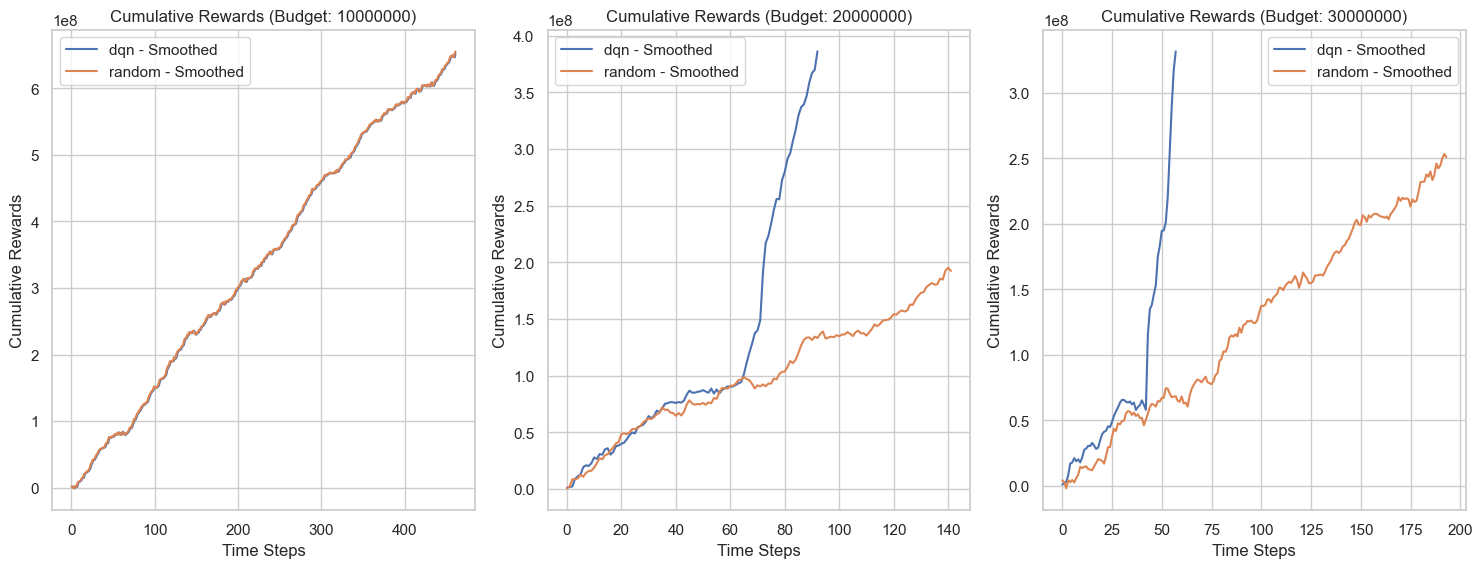

<Figure size 640x480 with 0 Axes>

In [45]:
def plot_cumulative_rewards_subplot(data, budgets=[10_000_000, 20_000_000, 30_000_000], column='rewards', experiment_types=['dqn', 'random'], window_size=1):
    num_budgets = len(budgets)
    # Ensure the directory exists
    output_dir = 'experiment_results/plots'
    os.makedirs(output_dir, exist_ok=True)
    
    # Create a 1x3 subplot grid
    fig, axs = plt.subplots(1, num_budgets, figsize=(15, 6))

    for i, budget in enumerate(budgets):
        ax = axs[i]

        for experiment in experiment_types:
            filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}").reset_index()
            cumulative_rewards = filtered_data.groupby("episodes")[column].sum()
            cumulative_rewards = cumulative_rewards.cumsum()
            # Calculate the moving average for smoothing
            smoothed_rewards = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

            #plt.plot(cumulative_rewards, label=f"{experiment} - Raw")
            ax.plot(smoothed_rewards, label=f"{experiment} - Smoothed")

        ax.set_xlabel('Time Steps')
        ax.set_ylabel('Cumulative Rewards')
        ax.set_title(f'Cumulative Rewards (Budget: {budget})')
        ax.legend()
        
    plot_path = os.path.join(output_dir, 'cumulative_rewards.png')
    plt.tight_layout()
    plt.savefig(plot_path)
    plt.show()


# Example usage
plot_cumulative_rewards_subplot(data, budgets=[10_000_000, 20_000_000, 30_000_000])

C:\Users\nande\AppData\Local\Temp\ipykernel_51488\2626065567.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='initial_budget', y='rewards', hue='experiment', data=data, estimator='sum', ci=None)


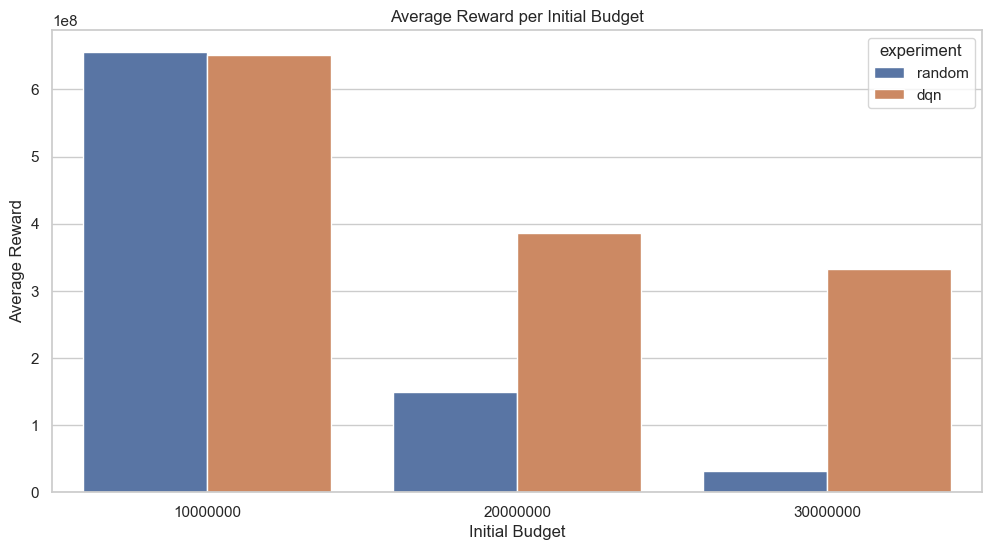

In [23]:
# Setting the aesthetic style of the plots
sns.set(style="whitegrid")

# Plot 1: Average Reward per Initial Budget
plt.figure(figsize=(12, 6))
sns.barplot(x='initial_budget', y='rewards', hue='experiment', data=data, estimator='sum', ci=None)
plt.title('Average Reward per Initial Budget')
plt.xlabel('Initial Budget')
plt.ylabel('Average Reward')
plt.show()


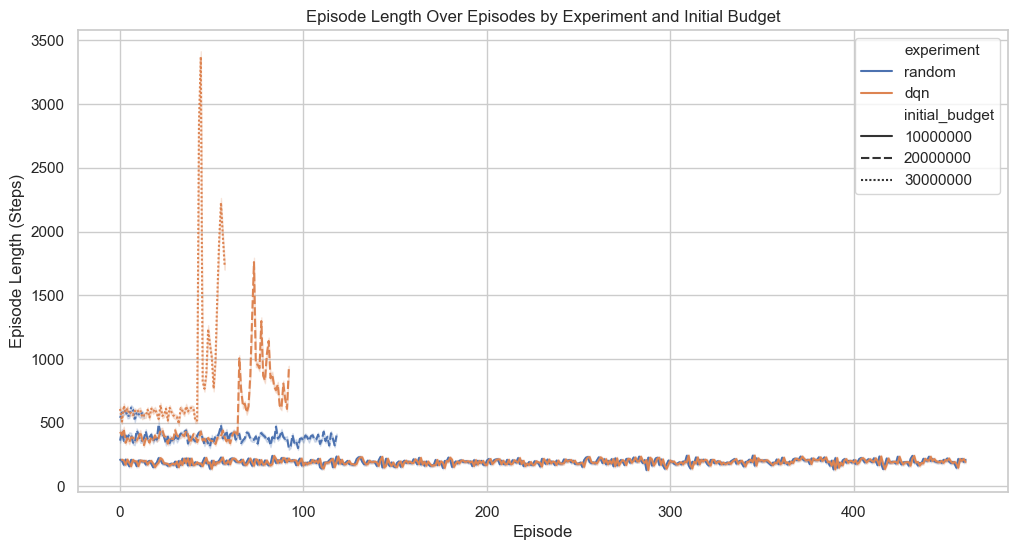

In [6]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='episodes', y='steps', hue='experiment', style='initial_budget', data=data)
plt.title('Episode Length Over Episodes by Experiment and Initial Budget')
plt.xlabel('Episode')
plt.ylabel('Episode Length (Steps)')
plt.show()


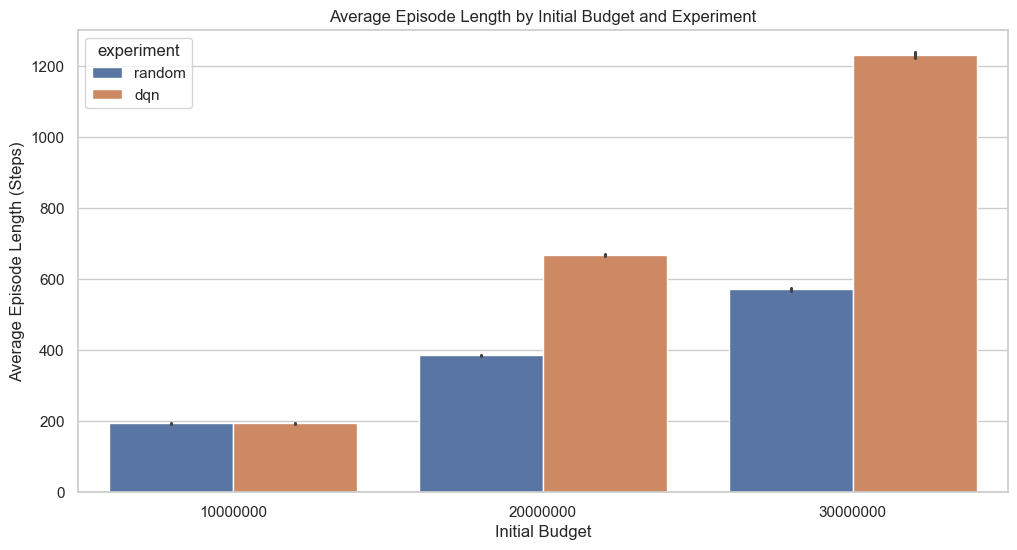

In [7]:
plt.figure(figsize=(12, 6))
sns.barplot(x='initial_budget', y='steps', hue='experiment', data=data)
plt.title('Average Episode Length by Initial Budget and Experiment')
plt.xlabel('Initial Budget')
plt.ylabel('Average Episode Length (Steps)')
plt.show()


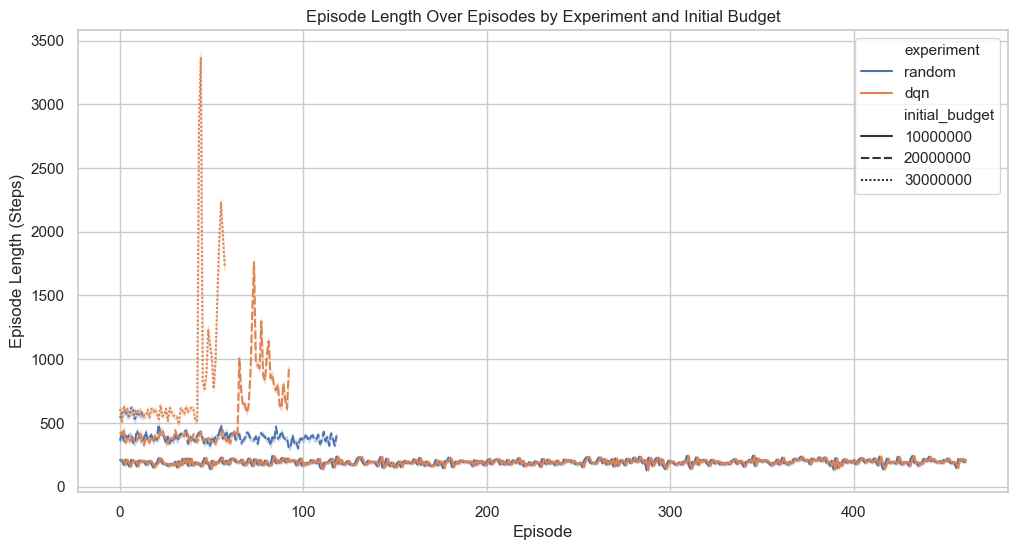

In [11]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='episodes', y='steps', hue='experiment', style='initial_budget', data=data)
plt.title('Episode Length Over Episodes by Experiment and Initial Budget')
plt.xlabel('Episode')
plt.ylabel('Episode Length (Steps)')
plt.show()


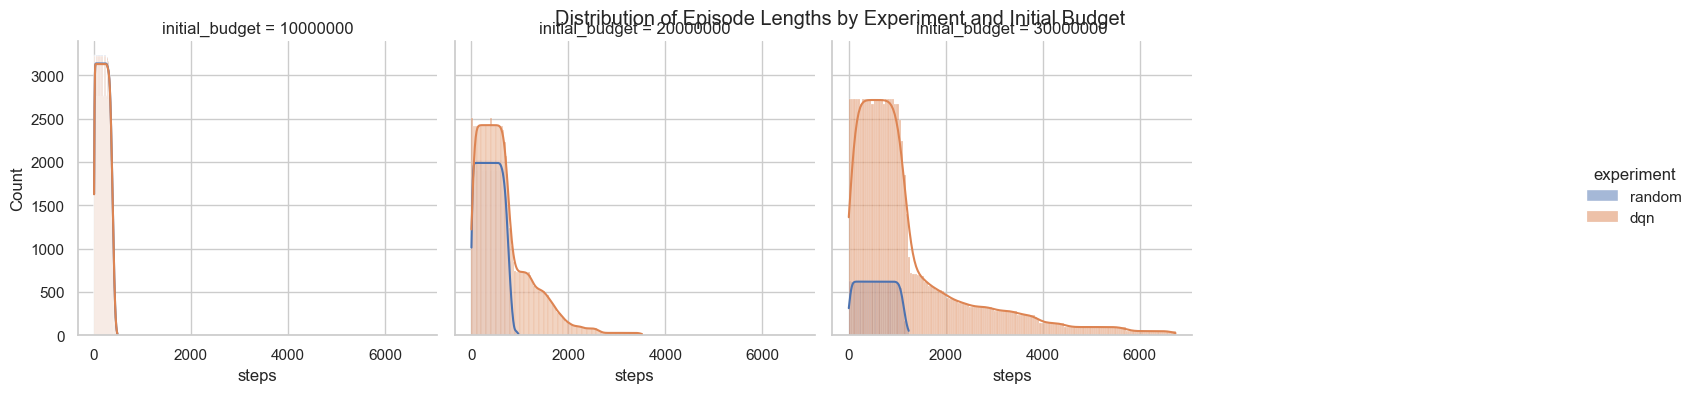

In [14]:
# Separate histograms for each initial budget
g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4)
g.map(sns.histplot, 'steps', kde=True, multiple='stack')
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')
plt.show()

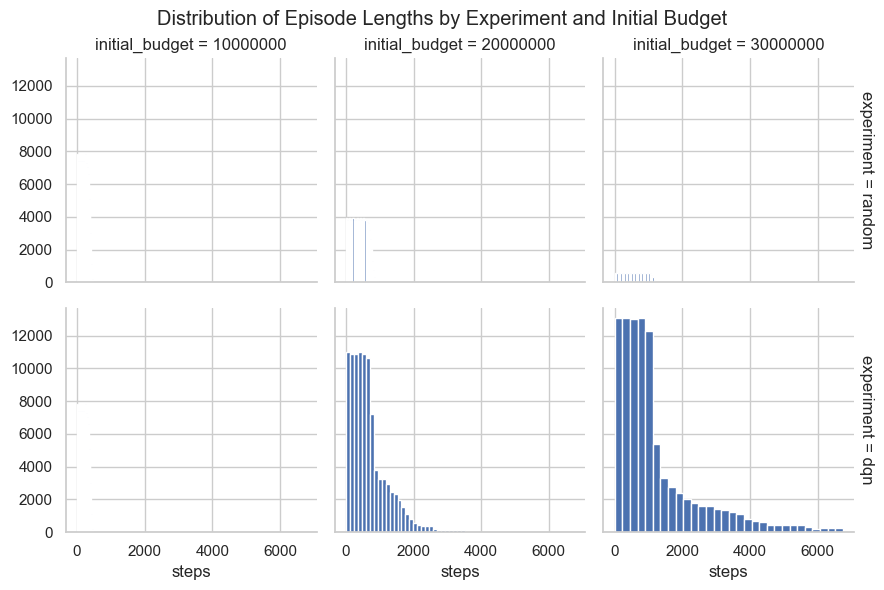

In [16]:
g = sns.FacetGrid(data, col='initial_budget', row='experiment', margin_titles=True)
g.map(plt.hist, 'steps', bins=30)
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Distribution of Episode Lengths by Experiment and Initial Budget')
plt.show()

  experiment  initial_budget         mean  median          std  min   max  \
0        dqn        10000000   193.923679   192.0   114.103931    1   483   
1        dqn        20000000   667.594864   533.0   561.865144    1  3520   
2        dqn        30000000  1231.491596   827.0  1260.750537    1  6741   
3     random        10000000   193.956737   192.0   114.119675    1   483   
4     random        20000000   386.031257   383.0   226.282102    1   970   
5     random        30000000   570.933568   570.0   330.629026    1  1237   

    count     iqr  
0  176294   192.0  
1   99068   606.0  
2   95904  1075.0  
3  176709   192.0  
4   90987   382.0  
5   15941   569.0  
Statistical analysis results saved to experiment_results/stats/episode_length_stats.csv


KeyboardInterrupt: 

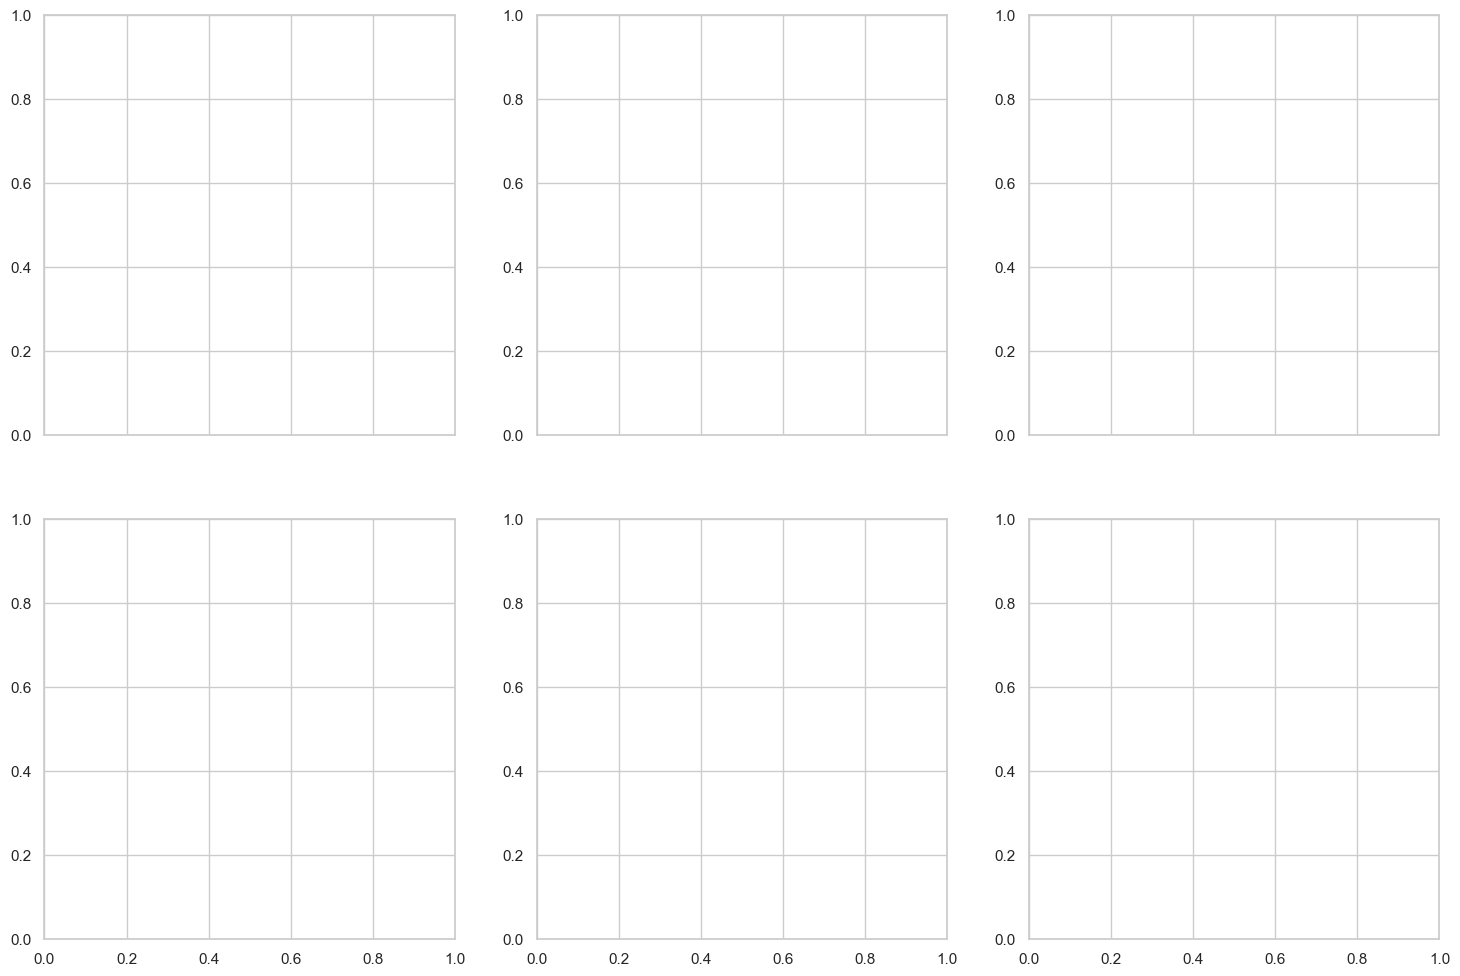

In [38]:

def plot_cumulative_rewards(data, budgets, column='rewards', experiment_types=['dqn', 'random'], window_size=1, save_path='plots'):
    # Set the style of seaborn
    sns.set(style="whitegrid")

    # Make sure the directory exists
    os.makedirs(save_path, exist_ok=True)

    # Define the number of subplots based on the number of budgets and experiment types
    fig, axes = plt.subplots(2, len(budgets), figsize=(18, 12), sharex='col')

    # We assume that the maximum number of episodes is consistent across all budgets
    max_episodes = data['episodes'].max()

    for j, row in enumerate(['Raw', 'Smoothed']):
        for i, budget in enumerate(budgets):
            ax = axes[j, i]
            for experiment in experiment_types:
                # Filter the data for the current experiment and budget
                filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}")
                # Calculate the cumulative rewards
                cumulative_rewards = filtered_data.groupby("episodes")[column].sum().cumsum()

                # If raw plot, skip smoothing
                if row == 'Raw':
                    rewards_to_plot = cumulative_rewards
                else:
                    # Calculate the moving average for smoothing
                    rewards_to_plot = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

                # Plot using seaborn lineplot
                sns.lineplot(x=filtered_data['episodes'], y=rewards_to_plot, ax=ax, label=f"{experiment}")

            # Set the title for each subplot in the top row
            if j == 0:
                ax.set_title(f'Budget: {budget}')
            ax.set_xlabel('Episodes')
            ax.set_ylabel(f'{row} Cumulative Rewards')
            ax.legend()
            ax.set_xlim(0, max_episodes)  # Set consistent x-axis limits

    plt.tight_layout()

    # Save the figure
    plot_file_path = os.path.join(save_path, 'cumulative_rewards_comparison.png')
    plt.savefig(plot_file_path)
    print(f"Plot saved to {plot_file_path}")

    plt.show()

# Example usage with a list of budgets
plot_cumulative_rewards(data, budgets=[10_000_000, 20_000_000, 30_000_000])

In [ ]:
df = data.pivot_table(index = "initial_budget", columns = ["experiment", "decision"], values ="budget",aggfunc='count')
df

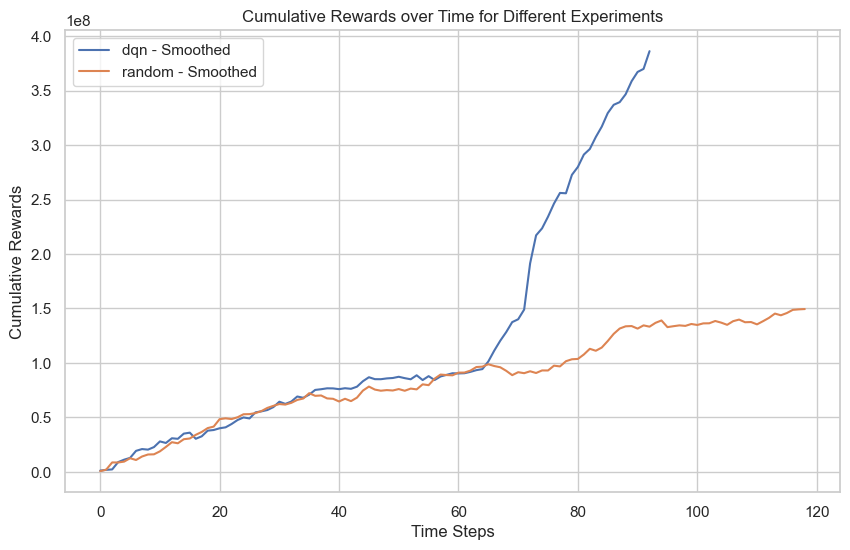

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def plot_cumulative_rewards(data, budget=1_000_000, column='rewards', experiment_types=['dqn', 'random'], window_size=1):
    plt.figure(figsize=(10, 6))

    for experiment in experiment_types:
        filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}").reset_index()
        cumulative_rewards = filtered_data.groupby("episodes")[column].sum()
        cumulative_rewards = cumulative_rewards.cumsum()
        # Calculate the moving average for smoothing
        smoothed_rewards = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

        #plt.plot(cumulative_rewards, label=f"{experiment} - Raw")
        plt.plot(smoothed_rewards, label=f"{experiment} - Smoothed")

    plt.xlabel('Time Steps')
    plt.ylabel('Cumulative Rewards')
    plt.title('Cumulative Rewards over Time for Different Experiments')
    plt.legend()
    plt.show()

# Example usage
plot_cumulative_rewards(data, budget=20_000_000)


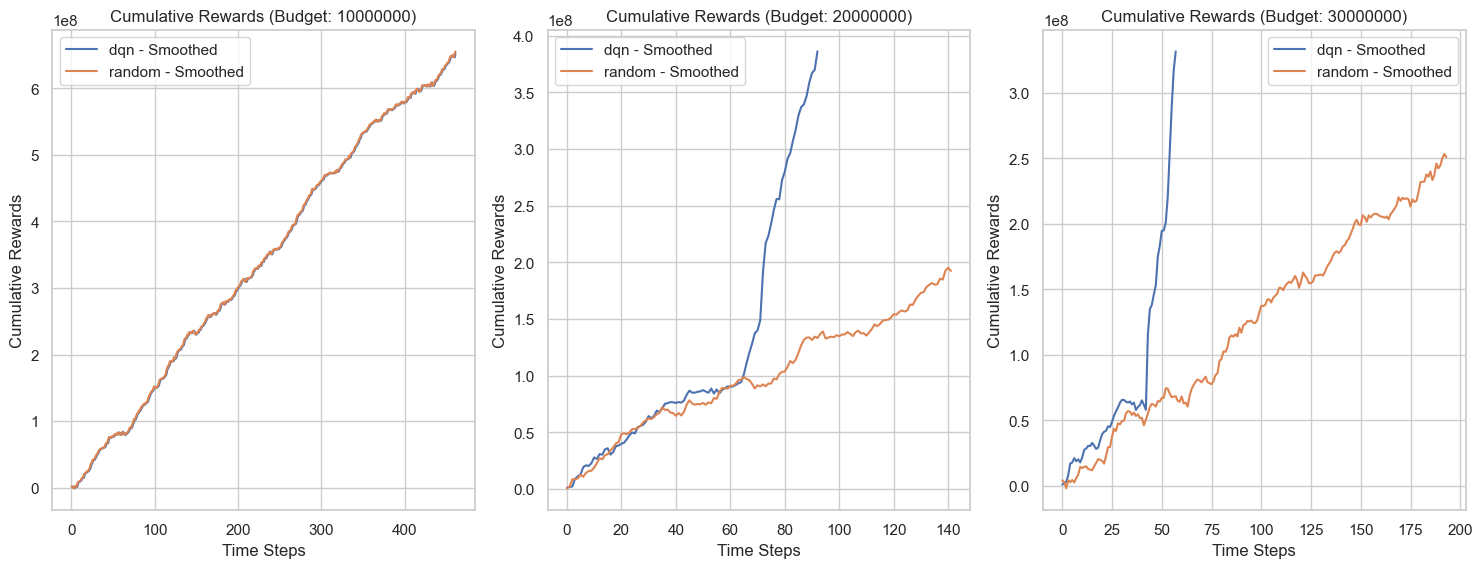

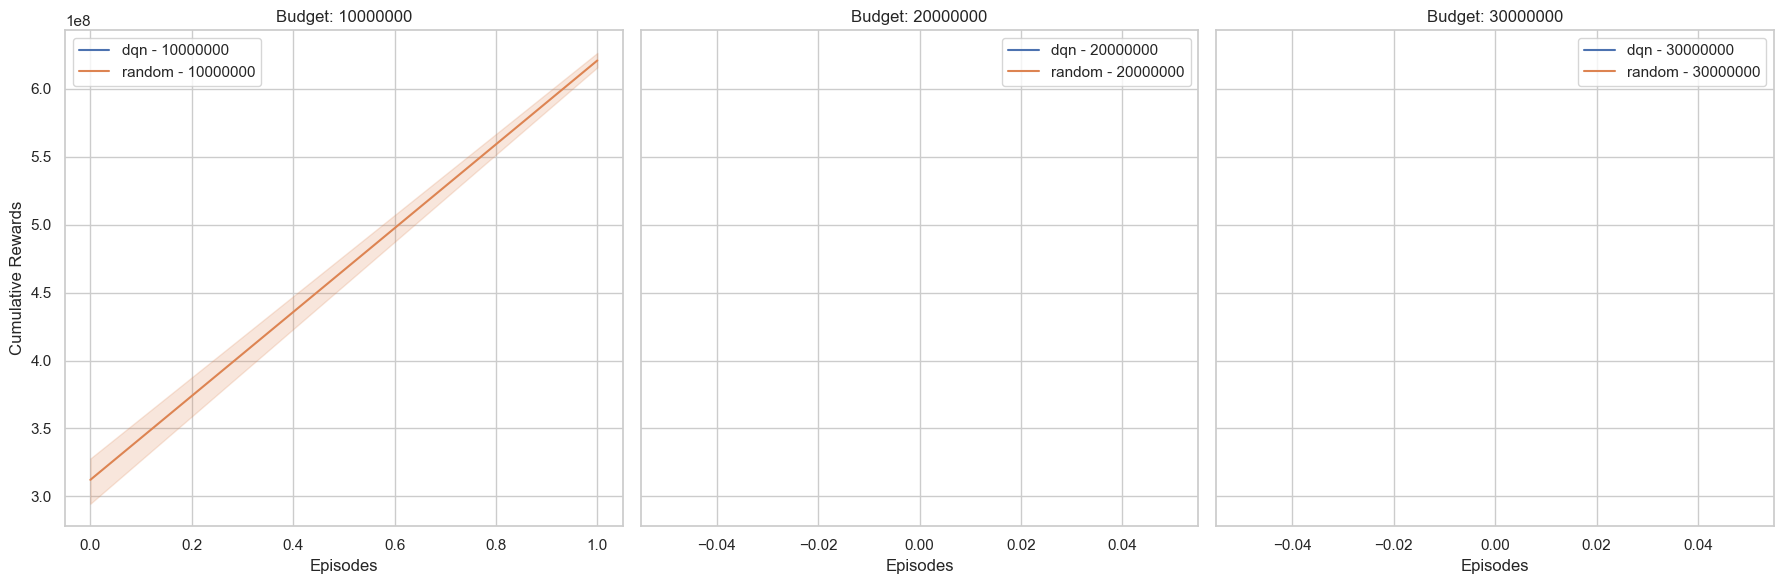

In [32]:
def plot_cumulative_rewards(data, budgets, column='rewards', experiment_types=['dqn', 'random'], window_size=1):
    # Set the style of seaborn
    sns.set(style="whitegrid")

    # Define the number of subplots based on the number of budgets
    fig, axes = plt.subplots(1, len(budgets), figsize=(18, 6), sharey=True)

    for i, budget in enumerate(budgets):
        ax = axes[i]
        for experiment in experiment_types:
            # Filter the data for the current experiment and budget
            filtered_data = data.query(f"experiment == '{experiment}' and initial_budget == {budget}")
            # Calculate the cumulative rewards
            cumulative_rewards = filtered_data.groupby("episodes")[column].sum().cumsum()
            # Calculate the moving average for smoothing
            smoothed_rewards = cumulative_rewards.rolling(window=window_size, min_periods=1).mean()

            # Plot using seaborn lineplot
            sns.lineplot(x=filtered_data['episodes'], y=smoothed_rewards, ax=ax, label=f"{experiment} - {budget}")

        # Set the title for each subplot
        ax.set_title(f'Budget: {budget}')
        ax.set_xlabel('Episodes')
        ax.set_ylabel('Cumulative Rewards')
        ax.legend()

    plt.tight_layout()
    plt.show()

# Example usage with a list of budgets
plot_cumulative_rewards(data, budgets=[10_000_000, 20_000_000, 30_000_000])

In [446]:
data.query('experiment=="dqn"').groupby(["initial_budget"])["episodes"].max()

initial_budget
10000000    461
20000000     92
30000000     57
Name: episodes, dtype: int64

<Axes: >

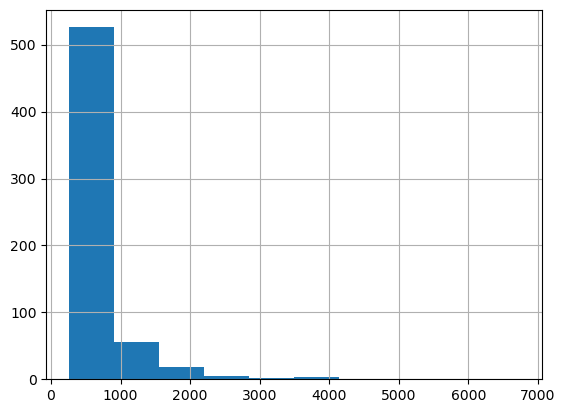

In [441]:
data.query('experiment=="dqn"').groupby(["initial_budget", "episodes"])["steps"].max().hist()

<Axes: >

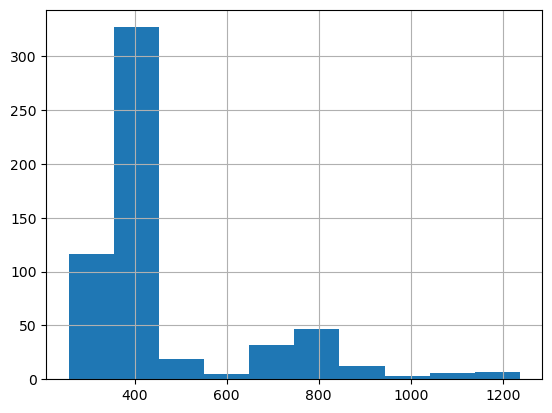

In [442]:
data.query('experiment=="random"').groupby(["initial_budget", "episodes"])["steps"].max().hist()

In [128]:

data.query("experiment =='dqn' and initial_budget == 15000000").rewards.sum()

98430862.13621572

In [129]:

data.query("experiment =='dqn' and initial_budget == 15000000").rewards.sum()/data.query("experiment =='random' and initial_budget == 15000000").rewards.sum()


2.250490693385203

In [52]:
data.query("experiment =='dqn' and initial_budget == 10000000").valor_indenizacao.sum()

564831053.31

In [53]:
data.query("initial_budget == 10000000").groupby("experiment")['valor_indenizacao'].describe()

,count,mean,std,min,25%,50%,75%,max
experiment,,,,,,,,
dqn,10786.0,52367.054822,72057.592181,0.10,12127.7525,29922.95,65026.8225,990000.0
random,10433.0,52851.485928,72549.534790,25.97,12196.8000,30259.60,65899.5700,990000.0


<Axes: >

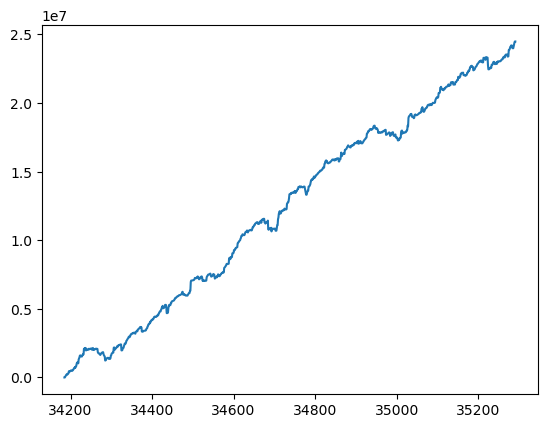

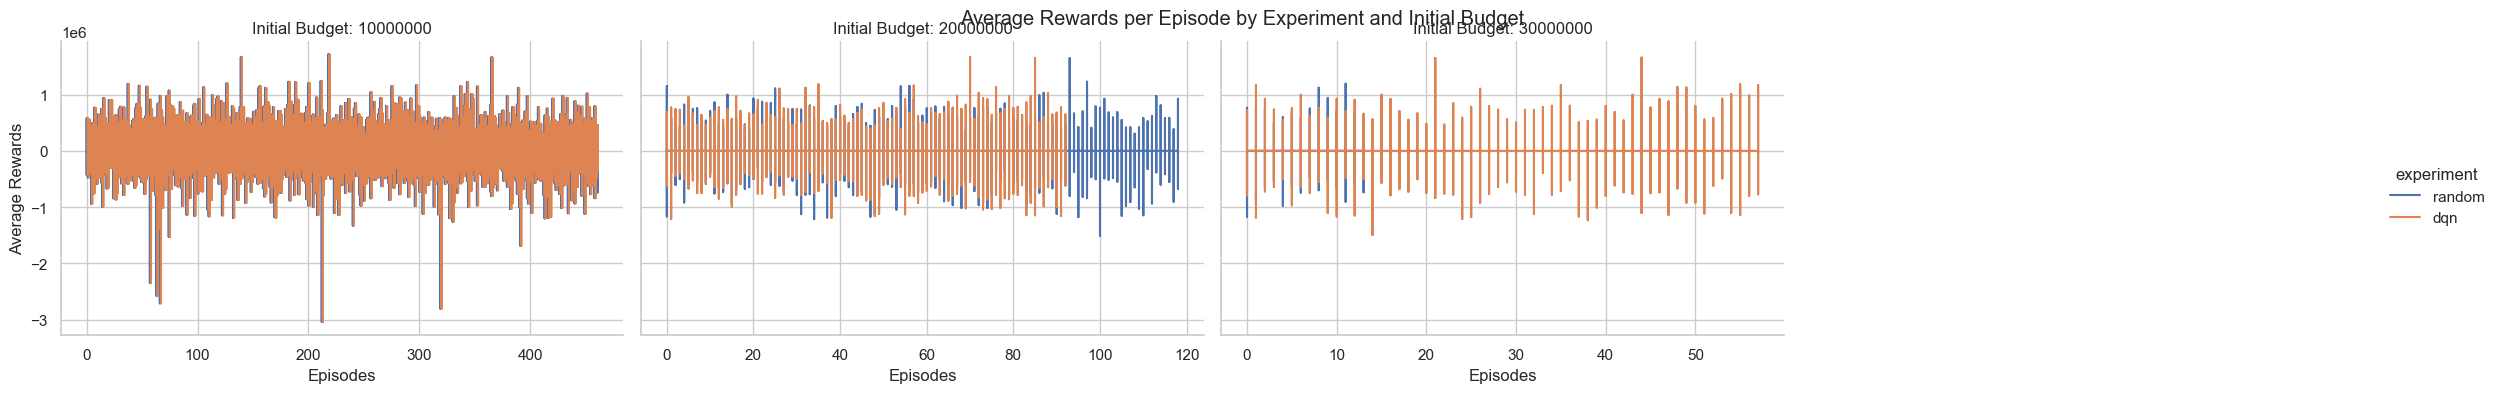

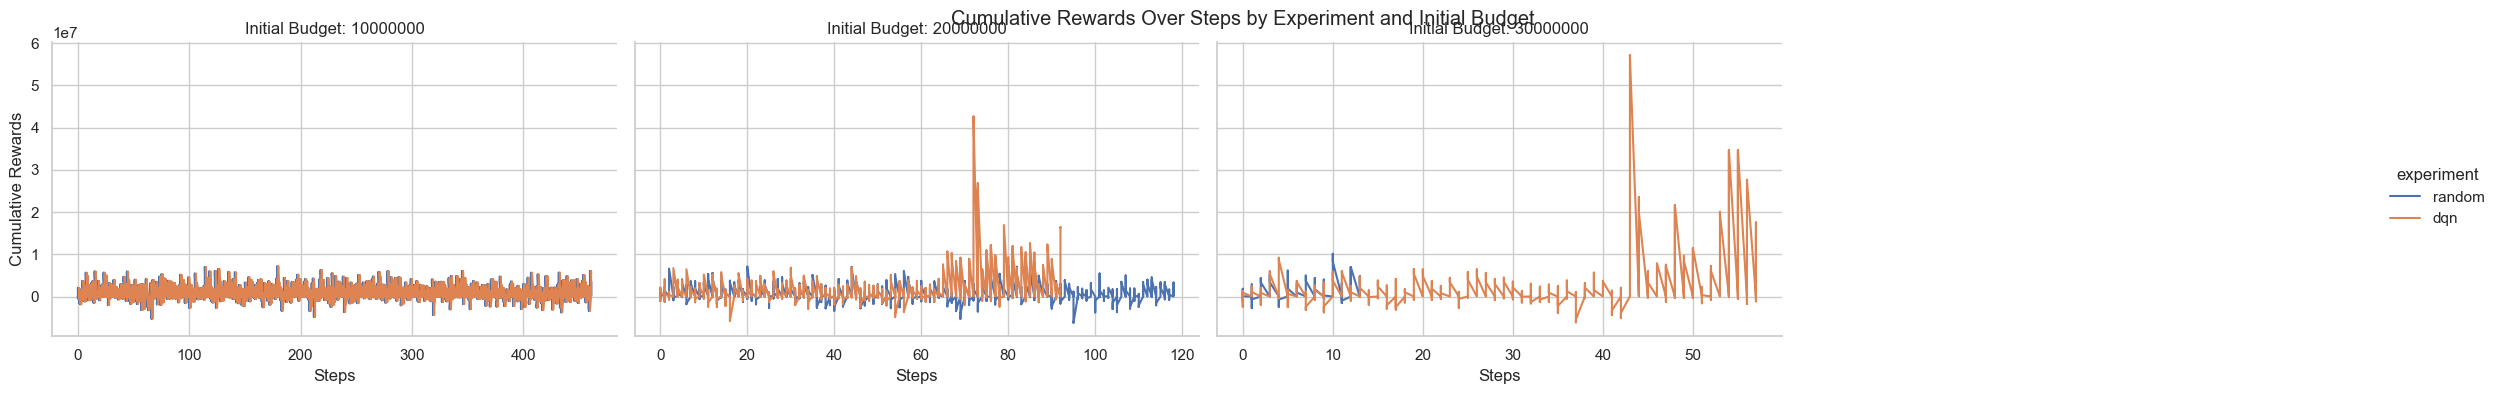

In [27]:

# Adding a cumulative reward column
data['cumulative_rewards'] = data.groupby(['experiment', 'initial_budget', 'episodes'])['rewards'].cumsum()

# Define a function to create faceted plots
def create_faceted_plot(data, x_col, y_col, title, xlabel, ylabel):
    g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4, aspect=1.5, sharex=False)
    g = g.map(plt.plot, x_col, y_col).add_legend()
    g.set_titles(col_template="Initial Budget: {col_name}")
    g.set_axis_labels(xlabel, ylabel)
    plt.subplots_adjust(top=0.9)
    g.fig.suptitle(title)

# 1. Episodic Metrics Plot
create_faceted_plot(data, 'episodes', 'rewards', 
                    'Average Rewards per Episode by Experiment and Initial Budget', 
                    'Episodes', 'Average Rewards')

# 2. Action vs Rewards Metrics Plot (if action data is available)
# Assuming 'actions' column exists or can be derived
# Uncomment and modify if applicable
# create_faceted_plot(data, 'actions', 'rewards', 
#                     'Average Rewards by Action, Experiment, and Initial Budget', 
#                     'Actions', 'Average Rewards')

# 3. Cumulative Rewards Plot
create_faceted_plot(data, 'episodes', 'cum_rewards', 
                    'Cumulative Rewards Over Steps by Experiment and Initial Budget', 
                    'Steps', 'Cumulative Rewards')

plt.show()

In [21]:
data["cum_rewards"] = data.groupby(["experiment", "initial_budget"])["rewards"].cumsum()

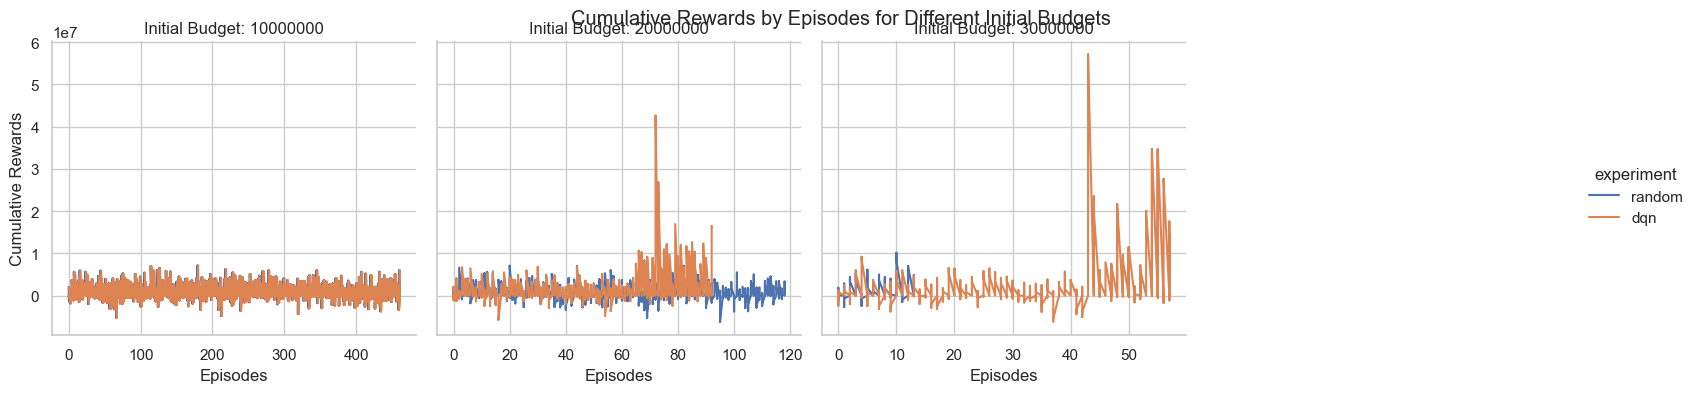

In [28]:
# Create a Faceted Line Plot for Cumulative Rewards by Episodes
def plot_cumulative_rewards_by_episodes(data):
    g = sns.FacetGrid(data, col='initial_budget', hue='experiment', col_wrap=4, height=4, aspect=1, sharex=False)
    g = g.map(plt.plot, 'episodes', 'cum_rewards').add_legend()
    g.set_titles(col_template="Initial Budget: {col_name}")
    g.set_axis_labels("Episodes", "Cumulative Rewards")
    plt.subplots_adjust(top=0.9)
    g.fig.suptitle('Cumulative Rewards by Episodes for Different Initial Budgets')

plot_cumulative_rewards_by_episodes(data)
plt.show()

In [ ]:

episodic_metrics = data.groupby(['episodes', 'experiment']).agg({'rewards': 'mean'}).reset_index()
plt.figure(figsize=(10, 6))
sns.lineplot(data=episodic_metrics, x='episodes', y='rewards', hue='experiment')
plt.title('Average Rewards per Episode by Experiment')
plt.xlabel('Episodes')
plt.ylabel('Average Rewards')
plt.show()

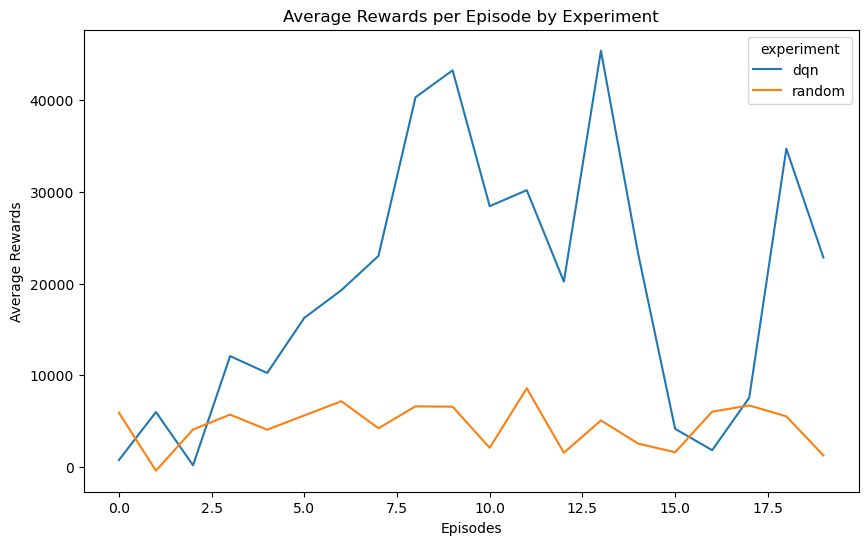

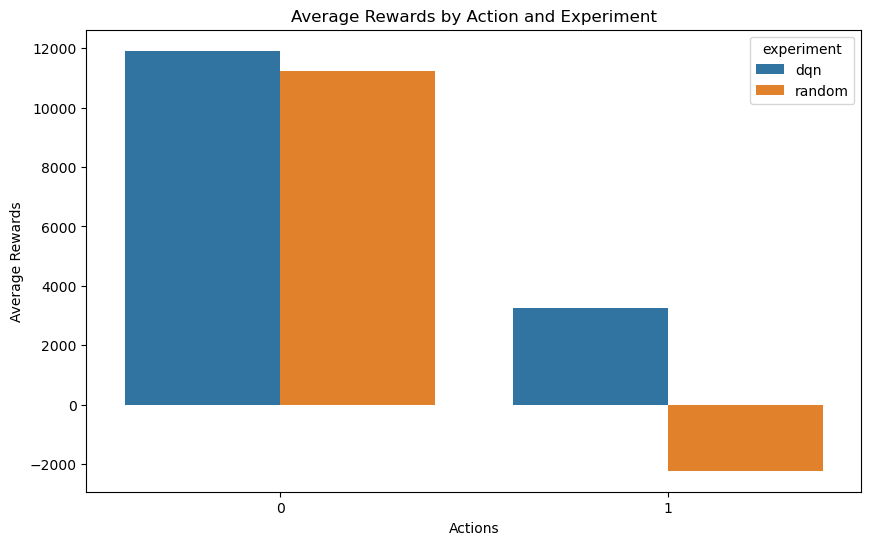

In [208]:
episodic_metrics = data.groupby(['episodes', 'experiment']).agg({'rewards': 'mean'}).reset_index()

## 2. Action vs Rewards Metrics
# Assuming 'actions' column exists or can be derived
action_rewards_metrics = data.groupby(['decision', 'experiment']).agg({'rewards': 'mean'}).reset_index()

## 3. Cumulative Rewards
data['cumulative_rewards'] = data.groupby(['experiment', 'initial_budget'])['rewards'].cumsum()

# Visualization
## Episodic Metrics Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=episodic_metrics, x='episodes', y='rewards', hue='experiment')
plt.title('Average Rewards per Episode by Experiment')
plt.xlabel('Episodes')
plt.ylabel('Average Rewards')
plt.show()

## Action vs Rewards Metrics Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=action_rewards_metrics, x='decision', y='rewards', hue='experiment')
plt.title('Average Rewards by Action and Experiment')
plt.xlabel('Actions')
plt.ylabel('Average Rewards')
plt.show()

## Cumulative Rewards Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=data, x='steps', y='cumulative_rewards', hue='experiment', style='initial_budget')
plt.title('Cumulative Rewards Over Steps by Experiment and Initial Budget')
plt.xlabel('Steps')
plt.ylabel('Cumulative Rewards')
plt.show()

In [ ]:
data.groupby(["experiment", "initial_budget","decision"])['rewards'].sum()

experiment  initial_budget  decision
dqn         1000000         0            9574513.11
                            1            8699206.80
            5000000         0                271.54
                            1                297.56
            10000000        0                400.92
                            1                116.31
            15000000        0                621.46
                            1               -199.09
random      1000000         0            8511411.78
                            1            9187327.77
            5000000         0           25459597.69
                            1           13673725.47
            10000000        0           47379758.61
                            1          -17722665.06
            15000000        0           55821502.64
                            1          -39284463.92
Name: rewards, dtype: float64

In [ ]:
data

,Unnamed: 0,episodes,decision,rewards,cum_rewards,budget,initial_budget,wc,woc,steps,...,third_digit_4,third_digit_5,third_digit_6,third_digit_7,third_digit_8,third_digit_9,third_digit_10,third_digit_11,valor_indenizacao,experiment
0,0,0,1,0.00,0.00,991270.46,1000000,0.00,0.00,1,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8729.54,random
1,1,0,1,78885.75,78885.75,916491.84,1000000,0.17,0.17,2,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,74778.62,random
2,2,0,1,32736.97,111622.72,885204.38,1000000,0.24,0.25,3,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,31287.46,random
3,3,0,1,57952.04,169574.75,830946.03,1000000,0.29,0.30,4,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,54258.35,random
4,4,0,1,-15034.59,154540.16,817584.49,1000000,0.30,0.32,5,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,13361.54,random
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78819,155,19,1,1.05,22.58,796556.21,5000000,0.56,0.54,156,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,31798.02,dqn
78820,156,19,1,-1.00,21.58,740135.21,5000000,0.50,0.53,157,...,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,56421.00,dqn
78821,157,19,1,-1.00,20.58,581654.27,5000000,0.53,0.53,158,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,158480.94,dqn
78822,158,19,1,1.00,21.58,333027.84,5000000,0.54,0.54,159,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,248626.43,dqn


<Axes: >

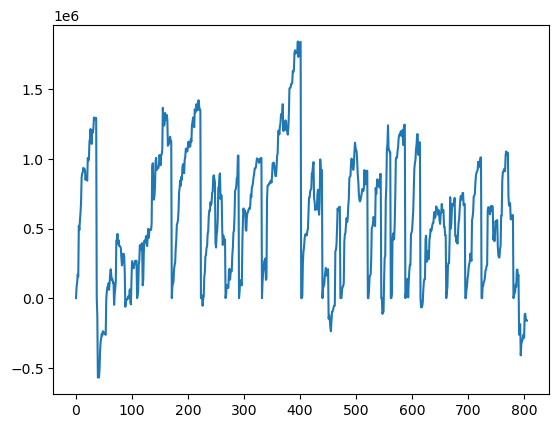

In [ ]:
data.query("initial_budget == 1000000 and experiment =='random'")['cum_rewards'].plot()

<Axes: >

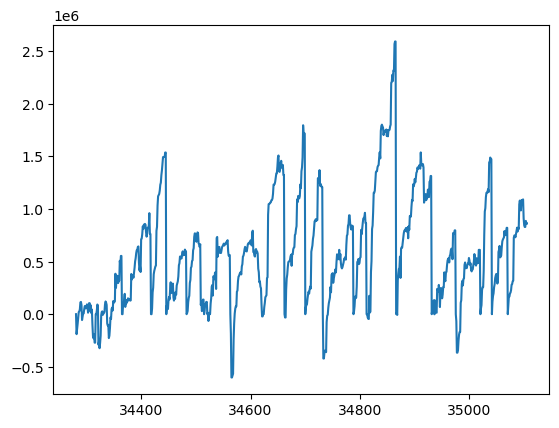

In [ ]:
data.query("initial_budget == 1000000 and experiment =='dqn'")['cum_rewards'].plot()

In [ ]:
data.query("initial_budget == 15000000").groupby("experiment").steps.sum()

experiment
dqn       1762289
random    1573308
Name: steps, dtype: int64

In [ ]:
data.groupby("experiment").episodes.max()

experiment
dqn       9
random    9
Name: episodes, dtype: int64

In [ ]:
data.query("initial_budget == 1000000 and experiment =='dqn'")['decision'].value_counts()

In [102]:
data.filter(regex='budget').columns

Index(['budget', 'initial_budget'], dtype='object')

In [103]:
data["pct_budget"] = data.budget / data.initial_budget
# Set Pandas display option to show the whole number
pd.set_option('display.float_format', '{:.2f}'.format)

In [104]:
summary_budget = data.query("decision ==1").pivot_table(index = ["experiment","initial_budget"], columns = ["episodes"], values = "valor_indenizacao", aggfunc='sum')

In [105]:
summary_budget

episodes                            0           1           2           3  \
experiment initial_budget                                                   
dqn        1000000          949829.08   864913.66   942368.62   962274.23   
           5000000         4984685.39  4978126.53  4881255.71  4966871.08   
           10000000        9989492.93  9584085.77  9897470.73  9945823.10   
           15000000       14992633.00 14985901.50 14988445.04 14995023.47   
random     1000000                NaN   944390.64   976531.99   725528.49   
           5000000                NaN  4995883.34  4955494.89  4835764.94   
           10000000               NaN  9993653.87  9980776.24  9953235.50   
           15000000               NaN 14981363.20 14982168.12 14865501.64   

episodes                            4           5           6           7  \
experiment initial_budget                                                   
dqn        1000000          975938.68   984227.99   993722.11   994619.44   
           5000000         4962571.04  4989457.36  4956345.82  4618532.37   
           10000000        9984767.40  9720733.10  9931943.52  9966100.26   
           15000000       14824853.53 14984557.54 14995123.24 14971777.58   
random     1000000          989821.71   905222.06   941167.28   997624.26   
           5000000         4968036.11  4822001.65  4951146.29  4972007.95   
           10000000        9921034.67  9799466.98  9966033.47  9998828.21   
           15000000       14719702.58 14930028.54 14990036.01 14801434.03   

episodes                            8           9  
experiment initial_budget                          
dqn        1000000          940886.01   997594.02  
           5000000         4994798.39  4987590.31  
           10000000        9940561.90  9982433.08  
           15000000       14978806.78 14894976.06  
random     1000000          947832.87   903239.60  
           5000000         4958954.32  4924987.16  
           10000000        9798423.17  9982715.82  
           15000000       14954407.17 14970019.43

In [109]:
import pandas as pd

# Assuming 'data' is your DataFrame

# Create a pivot table to count the decisions
pivot_table = data.query("episodes<10").pivot_table(index="initial_budget", columns=["experiment", "decision"], values="budget", aggfunc='count')

# Normalize the counts to get percentages for each group separately
percentage_table = pivot_table.copy()

for group in ['dqn', 'random']:
    group_columns = [col for col in pivot_table.columns if col[0] == group]
    total_counts_group = pivot_table[group_columns].sum(axis=1)
    percentage_table[group_columns] = pivot_table[group_columns].div(total_counts_group, axis=0) * 100

# Display the percentage table
print(percentage_table)



experiment       dqn       random      
decision           0     1      0     1
initial_budget                         
1000000        50.89 49.11  49.24 50.76
5000000        51.12 48.88  48.37 51.63
10000000       50.33 49.67  50.51 49.49
15000000       50.78 49.22  50.98 49.02


In [110]:
def perform_statistical_tests(data):
    #df = data.query("episodes<10").copy(deep = True)
    # Flatten the multi-level column structure for easier processing
    df.columns = ['_'.join(map(str, col)).strip() for col in df.columns.values]

    # Initialize a dictionary to store test results
    results = {}

    # Independent Samples t-test and Mann-Whitney U Test between dqn and random for each decision
    for decision in [0, 1]:
        dqn_col = f'dqn_{decision}'
        random_col = f'random_{decision}'

        # T-test
        t_stat, t_p = stats.ttest_ind(df[dqn_col], df[random_col], equal_var=False)
        results[f'T-test Decision {decision}'] = t_p

        # Mann-Whitney U Test
        u_stat, u_p = stats.mannwhitneyu(df[dqn_col], df[random_col])
        results[f'Mann-Whitney U Test Decision {decision}'] = u_p

    # Chi-Square Test of Independence
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        chi2, chi_p, _, _ = stats.chi2_contingency(obs)
        results[f'Chi-Square Test Budget {budget}'] = chi_p

    # Fisher's Exact Test
    for budget in df.index:
        obs = df.loc[budget, [f'dqn_{i}' for i in [0, 1]] + [f'random_{i}' for i in [0, 1]]].values.reshape(2, 2)
        _, fisher_p = stats.fisher_exact(obs)
        results[f'Fisher Exact Test Budget {budget}'] = fisher_p

    return pd.DataFrame.from_dict(results, orient='index', columns=['P-Value'])
test_results = perform_statistical_tests(df)
print(test_results)


KeyError: 'dqn_0'